# Do Blender ao NVIDIA Sionna RT

**Objetivo:** Aprender a importar um modelo 3D do Blender, para o NVIDIA Sionna RT, atribuir materiais eletromagnéticos e realizar simulações de propagação de ondas de rádio.

### Objetivos de aprendizagem

1. Criar uma cena XML no Mitsuba 3.
2. Carregar a cena no Sionna RT.
3. Configurar materiais de rádio.
4. Adicionar transmissores e receptores.
5. Calcular os percursos de propagação das ondas de rádio.
6. Visualizar os percursos de propagação obtidos.

# 1 Importando as dependências

In [1]:

import os
import numpy as np
import matplotlib.pyplot as plt

import sionna
import sionna.rt

import mitsuba as mi

from sionna.rt import (
    load_scene,
    SceneObject,
    ITURadioMaterial,
    PlanarArray,
    Transmitter,
    Receiver,
    PathSolver,
    Camera
)

print("Sionna version:", sionna.__version__)
print("Mitsuba variant:", mi.variant())

Sionna version: 2.2.0
Mitsuba variant: cuda_ad_mono_polarized


# 2 Definindo o caminho do arquivo a ser importado

Neste tutorial, utilizaremos o arquivo OBJ chamado `penger.obj`.

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()

OBJ_FILE = PROJECT_DIR / "penger.obj"

print("OBJ file:", OBJ_FILE)
print("File exists:", OBJ_FILE.exists())

if not OBJ_FILE.exists():
    print("Please export your Blender model before continuing.")

OBJ file: /home/user/UFC/minicurso_sionna/notebooks/blender/penger.obj
File exists: True


# 3 Compreendendo a cena XML do Mitsuba

Esta é uma etapa particularmente importante.

O Sionna RT carrega cenas externas utilizando o formato XML do Mitsuba 3.

O arquivo XML descreve:

- Geometria.
- Nomes dos arquivos de malha (_mesh_).
- Materiais.
- Identificadores dos objetos.

Vamos criar uma cena XML simples que faça referência ao arquivo OBJ exportado do Blender.

O Sionna reconhece identificadores de materiais que começam com `mat-itu_` e pode convertê-los em materiais de rádio do tipo ITU.

Neste exemplo, utilizaremos o concreto como material.

**Importante:** O código XML apresentado a seguir serve como ponto de partida. A geometria e os parâmetros dos materiais devem ser adaptados à sua simulação específica.

In [3]:
XML_FILE = PROJECT_DIR / "scene.xml"

scene_xml = """<?xml version="1.0"?>
<scene version="3.0.0">

    <bsdf type="diffuse" id="mat-itu_concrete">
        <rgb name="reflectance" value="0.5, 0.5, 0.5"/>
    </bsdf>

    <shape type="obj" id="penger">
        <string name="filename" value="penger.obj"/>
        <ref id="mat-itu_concrete"/>
    </shape>

</scene>
"""

XML_FILE.parent.mkdir(parents=True, exist_ok=True)

XML_FILE.write_text(scene_xml)

print("XML scene created:", XML_FILE)

XML scene created: /home/user/UFC/minicurso_sionna/notebooks/blender/scene.xml


## Por que utilizamos XML?

O arquivo XML conecta a geometria exportada ao Mitsuba e ao Sionna.

A propriedade `filename` faz referência à malha OBJ.

O identificador `mat-itu_concrete` informa ao Sionna que o material deve ser interpretado como um material de rádio do tipo concreto, baseado no modelo ITU.

Isso é diferente de simplesmente atribuir uma cor ao objeto no Blender.

# 4. Carregando o objeto do Blender no Sionna

Agora podemos carregar a cena XML.

Certifique-se de que os arquivos `scene.xml` e `building.obj` estejam localizados no mesmo diretório.

In [4]:
scene = load_scene(str(XML_FILE))

print("Scene loaded successfully!")
print("Objects in scene:")

for name, obj in scene.objects.items():
    print(name, obj)

Scene loaded successfully!
Objects in scene:
merged-shapes <sionna.rt.scene_object.SceneObject object at 0x72f438865640>


## 4.1 Visualizando a cena importada

O Sionna disponibiliza uma ferramenta interativa de visualização da cena.

Esse recurso é útil para verificar se:

- A geometria foi importada corretamente.
- O objeto possui as dimensões adequadas.
- O objeto está posicionado corretamente.
- A cena está sendo exibida corretamente.

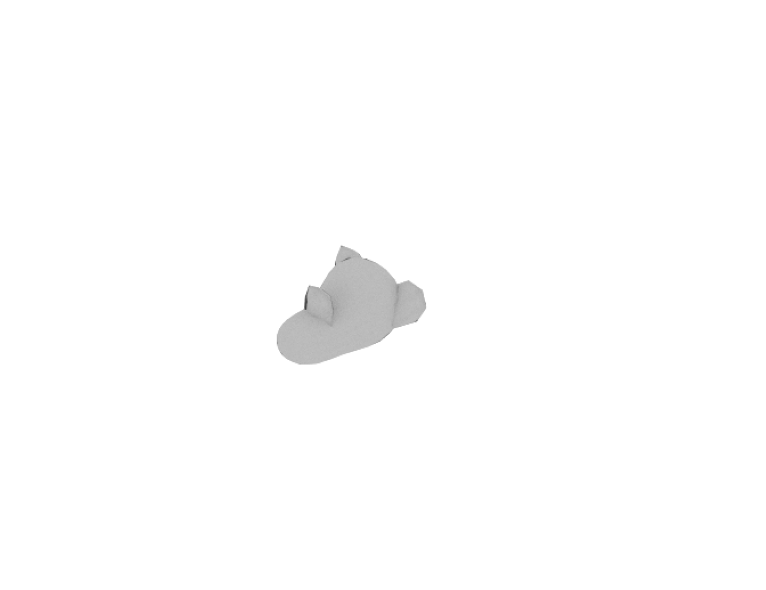

In [5]:
my_cam = Camera(position=[-5,5,5], look_at=[0,0,0])
scene.render(camera=my_cam);

# 5 Compreendendo os materiais eletromagnéticos

Em simulações de propagação de ondas de rádio, os materiais influenciam os fenômenos de reflexão, transmissão e absorção.

Alguns exemplos incluem:

- Concreto.
- Metal.
- Vidro.
- Madeira.

O Sionna disponibiliza materiais de rádio baseados nos modelos da ITU (União Internacional de Telecomunicações).

Diferentemente dos materiais visuais convencionais do Blender, esses materiais descrevem propriedades eletromagnéticas.

Por exemplo, podemos inspecionar os materiais associados à cena que importamos.

In [6]:
print("Available radio materials:")

for name, material in scene.radio_materials.items():
    print(name, material)

Available radio materials:
itu_concrete ITURadioMaterial type=concrete
                 eta_r=5.240
                 sigma=0.123
                 thickness=0.100
                 scattering_coefficient=0.000
                 xpd_coefficient=0.000


## 5.1 Atribuindo um material de rádio programaticamente

O Sionna também permite carregar diretamente uma malha OBJ utilizando a classe `SceneObject`.

Essa é uma alternativa à definição da malha por meio de um arquivo XML.

O exemplo a seguir cria um objeto de concreto de forma independente.

In [7]:
concrete = ITURadioMaterial(
    name="custom_concrete",
    itu_type="concrete",
    thickness=0.1
)

penger_2 = SceneObject(
    fname=str(OBJ_FILE),
    name="penger_2",
    radio_material=concrete,
    position=[0, 0.5, 2]
)

Para adicionar à cena um objeto criado programaticamente, utilize a interface de edição de cenas documentada pelo Sionna.

Para uma primeira importação, o fluxo de trabalho utilizando XML, apresentado anteriormente, é mais fácil de reproduzir e inspecionar.

# 6 Definindo a frequência de operação

A propagação de ondas de rádio depende fortemente da frequência.

Neste exemplo, utilizaremos a frequência de 3,5 GHz.

In [8]:
frequency = 3.5e9

scene.frequency = frequency

print("Frequency:", scene.frequency, "Hz")
print("Wavelength:", scene.wavelength, "m")

Frequency: [3.5e+09] Hz
Wavelength: [0.085655] m


# 7 Configurando os arranjos de antenas

O Sionna exige a definição de arranjos de antenas para os transmissores e receptores.

Começaremos com arranjos simples, compostos por um único elemento.

O diagrama de radiação isotrópico é útil para simulações introdutórias, pois evita a necessidade de considerar a direcionalidade da antena nesta etapa.

In [9]:
scene.tx_array = PlanarArray(
    num_rows=1,
    num_cols=1,
    vertical_spacing=0.5,
    horizontal_spacing=0.5,
    pattern="iso",
    polarization="V"
)

scene.rx_array = PlanarArray(
    num_rows=1,
    num_cols=1,
    vertical_spacing=0.5,
    horizontal_spacing=0.5,
    pattern="iso",
    polarization="V"
)

print("Transmitter and receiver arrays configured.")


Transmitter and receiver arrays configured.


# 8 Adicionando transmissores e receptores

Agora vamos introduzir os dispositivos de comunicação sem fio.

As posições apresentadas abaixo são apenas exemplos.

**Você deve adaptá-las às dimensões e às coordenadas do seu modelo criado no Blender.**

In [10]:
tx = Transmitter(
    name="tx",
    position=[-5, 0.5, 2]
)

rx = Receiver(
    name="rx",
    position=[5, 0.5, 2]
)

scene.add(tx)
scene.add(rx)
scene.add(penger_2)

tx.look_at(rx)

print("Transmitter:", tx.position)
print("Receiver:", rx.position)

Transmitter: [[-5, 0.5, 2]]
Receiver: [[5, 0.5, 2]]


# 9 Calculando os percursos de propagação das ondas de rádio

Agora chegamos à etapa mais interessante\!

O Sionna RT utiliza a classe `PathSolver` para calcular os percursos de propagação entre transmissores e receptores.

Dependendo da cena e da configuração do solucionador (_solver_), os percursos podem incluir:

- Propagação em linha de visada (_Line-of-Sight – LoS_).
- Reflexões.
- Difrações.
- Espalhamento (_Scattering_).

In [11]:
path_solver = PathSolver()

paths = path_solver(scene=scene,
                    max_depth=5,
                    los=True,
                    specular_reflection=True,
                    refraction=True,
                    synthetic_array=False,
                    seed=41)

# 10 Visualizando os percursos de propagação

Podemos visualizar a cena e os percursos de propagação calculados pelo Sionna RT.

In [12]:
scene.preview(
    paths=paths,
    resolution=[640, 580]
)


# 11. Conclusão

Parabéns! Você aprendeu como importar cenas e objetos do Blender no Sionna RT!

## Documentação oficial

- Sionna: https://nvlabs.github.io/sionna/
- Sionna RT scenes: https://nvlabs.github.io/sionna/rt/api/scene.html
- Sionna RT scene objects: https://nvlabs.github.io/sionna/rt/api/scene_object.html
- Sionna RT introduction: https://nvlabs.github.io/sionna/rt/tutorials/Introduction.html
- Mitsuba 3 scene format: https://mitsuba.readthedocs.io/en/latest/src/key_topics/scene_format.html